# Correcting correlations for attenuation: simulation and analytic decision boundaries

**Structure**
1. Imports
2. Equations
3. Shared helpers (reliability, noise ceiling, axis formatting, saving)
4. Monte Carlo simulation
5. RMSE of r vs r_unbiased (closed forms and exact simulation) and decision-boundary plots
6. **Run**: set parameters and call any of the plotting functions

**Terminology.** *Reliability* $Rel$ is a property of one measure: the share of variance in a subject's
mean across $k$ repeats that reflects true individual differences, $Rel = \sigma^2_T / (\sigma^2_T + \sigma^2_W / k)$.
The *noise ceiling* for a correlation between two measures is $r_{\mathrm{ceiling}} = \sqrt{Rel_x Rel_y}$, so that
$E[r] \approx \rho \, r_{\mathrm{ceiling}}$. When both measures have the same reliability, $r_{\mathrm{ceiling}} = Rel$.
The analytic section assumes equal reliabilities.

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib.lines import Line2D
from scipy.stats import pearsonr
from dataclasses import dataclass
from typing import List, Optional, Sequence, Tuple
from IPython.display import display, Math

In [59]:
display(Math(r"""
\begin{align}
Rel_{\text{split-half}} &= \frac{2 r_{\text{half}}}{1 + r_{\text{half}}} \tag{1} \\[1.5em]
r_{\text{ceiling}} &= \sqrt{Rel_x Rel_y}, \qquad \rho \approx \frac{r}{r_{\text{ceiling}}}, \qquad
r_{\text{unbiased}} = \frac{r}{r_{\text{ceiling}}} \tag{2} \\[1.5em]
\widehat{\text{Var}}(r) &\approx \frac{(1 - r^2)^2}{N - 1} \tag{3} \\[1.5em]
\widehat{\text{MSE}}_{r} &= \widehat{\text{Var}}(r) + \widehat{\text{Bias}}(r)^2
= \frac{(1 - r^2)^2}{N - 1} + \left(\frac{r}{r_{\text{ceiling}}} - r\right)^2 \tag{4} \\[1.5em]
\widehat{\text{MSE}}_{r_{\text{unbiased}}} &= \frac{\widehat{\text{Var}}(r)}{r_{\text{ceiling}}^2}
= \frac{(1 - r^2)^2}{r_{\text{ceiling}}^2 (N - 1)} \tag{5} \\[1.5em]
\text{Correct when } \frac{\text{RMSE}_{r_{\text{unbiased}}}}{\text{RMSE}_{r}} < 1
&\iff r_{\text{ceiling}} < \frac{r^2 - \widehat{\text{Var}}(r)}{r^2 + \widehat{\text{Var}}(r)} \tag{6}
\end{align}
"""))
# Note: (5) treats r_ceiling as known. In practice it is estimated from the same data.
# That adds variance, but the reliability error is positively correlated with the error in r,
# which partly cancels it, so (5) is NOT a lower bound (see delta_rmse_components). The large
# departures are at small N / high noise, driven by near-zero reliability estimates; there the
# raw r_unbiased has infinite variance, and only a clipped estimator has a well-defined RMSE.
# Figures therefore default to method='simulation' with clipping.

<IPython.core.display.Math object>

In [166]:
# =============================================================================
# Shared helpers
# =============================================================================

def reliability_of_mean(between_var, within_var, k):
    """True reliability of a subject's mean over k repeats: σ²_T / (σ²_T + σ²_W / k)."""
    return between_var / (between_var + within_var / k)


def calculate_r_ceiling_from_k(k, base_r_ceiling=0.75, base_k=2):
    """
    Spearman-Brown: reliability at k repeats, given reliability base_r_ceiling at base_k repeats.
    Equals the noise ceiling when both measures have the same reliability.
    """
    noise_to_signal = base_k * (1 - base_r_ceiling) / base_r_ceiling   # = σ²_W / σ²_T
    return 1 / (1 + noise_to_signal / k)


def format_n_axis(ax, n_min, n_max, ticks=(10, 20, 50, 100, 200, 500), label=r'Observers $N$'):
    ax.set_xscale('log')
    ax.set_xlim(n_min, n_max)
    ticks = [t for t in ticks if n_min <= t <= n_max]
    ax.xaxis.set_major_locator(ticker.FixedLocator(ticks))
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    if label:
        ax.set_xlabel(label, fontsize=20)


def format_noise_axis(ax, r_ceil_min, ticks=None):
    """Y axis is r_ceiling, displayed as measurement noise (1 - r_ceiling), noise-free at the bottom."""
    ax.set_ylim(1.0, r_ceil_min)
    if ticks is None:
        ticks = np.round(np.arange(np.ceil(r_ceil_min * 10) / 10, 1.0001, 0.1), 1)
    ax.set_yticks(ticks)
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{1 - y:.1f}"))
    ax.set_ylabel(r'Measurement noise $1 - r_{\mathrm{ceiling}}$', fontsize=20)


def finish_axis(ax, title=None):
    if title:
        ax.set_title(title, fontsize=20)
    ax.tick_params(axis='both', labelsize=16)
    ax.grid(True, which='both', ls='--', linewidth=0.8, alpha=0.5)
    ax.set_box_aspect(1)


def save_figure(fig, save_path=None, colab_download=False):
    """Save at 300 dpi. In Google Colab, optionally trigger a browser download."""
    if not save_path:
        return
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved figure to {save_path}")
    if colab_download:
        try:
            from google.colab import files
            files.download(save_path)
        except ImportError:
            pass

In [167]:
# =============================================================================
# Monte Carlo simulation
# =============================================================================

@dataclass
class TaskParameters:
    between_var: float  # true individual differences (σ²_T)
    within_var: float   # measurement noise per repeat (σ²_W)
    mean: float = 0.0
    name: str = "task"

    def reliability(self, k):
        return reliability_of_mean(self.between_var, self.within_var, k)


def noise_ceiling(task1: TaskParameters, task2: TaskParameters, k):
    """Theoretical noise ceiling √(R1·R2) for means over k repeats."""
    return np.sqrt(task1.reliability(k) * task2.reliability(k))


def estimate_reliability(measurements: np.ndarray) -> float:
    """
    Reliability of the mean of k repeats, estimated from data (n_subjects, k).
    The variance of observed means includes noise (σ²_W / k), so it is subtracted:
        R = 1 - (σ̂²_W / k) / Var(means)
    Can be negative in small samples; callers must handle that.
    """
    k = measurements.shape[1]
    if k < 2:
        raise ValueError("Need at least 2 repeats to estimate reliability.")
    var_means = measurements.mean(axis=1).var(ddof=1)
    within_var = measurements.var(axis=1, ddof=1).mean()
    if var_means <= 0:
        return np.nan
    return 1 - (within_var / k) / var_means


def simulate_data(task1, task2, n_subjects, n_repeats, true_correlation, rng):
    """Return two (n_subjects, n_repeats) arrays of noisy measurements."""
    cov_xy = true_correlation * np.sqrt(task1.between_var * task2.between_var)
    cov = [[task1.between_var, cov_xy], [cov_xy, task2.between_var]]
    true = rng.multivariate_normal([task1.mean, task2.mean], cov, size=n_subjects)
    m1 = true[:, [0]] + rng.normal(0, np.sqrt(task1.within_var), (n_subjects, n_repeats))
    m2 = true[:, [1]] + rng.normal(0, np.sqrt(task2.within_var), (n_subjects, n_repeats))
    return m1, m2


def run_simulation(task1, task2, n_subjects, n_repeats, true_correlation, n_iterations, rng,
                   clip=True):
    """
    clip=True: r_unbiased is truncated to [-1, 1] and set to sign(r) when a reliability estimate
    is <= 0 (no iterations dropped). clip=False: raw ratio, invalid iterations dropped; note its
    variance is infinite in theory, so SD/RMSE at small N and few repeats will not stabilise.
    """
    naive = np.empty(n_iterations)
    corrected = np.full(n_iterations, np.nan)
    n_clipped = 0

    for it in range(n_iterations):
        m1, m2 = simulate_data(task1, task2, n_subjects, n_repeats, true_correlation, rng)
        r, _ = pearsonr(m1.mean(axis=1), m2.mean(axis=1))
        naive[it] = r
        rel1, rel2 = estimate_reliability(m1), estimate_reliability(m2)
        # Both reliabilities must be positive: two negative values would otherwise
        # give a positive product and a spurious "valid" correction.
        if rel1 > 0 and rel2 > 0:
            corrected[it] = r / np.sqrt(rel1 * rel2)
        if clip and (np.isnan(corrected[it]) or abs(corrected[it]) > 1):
            corrected[it] = np.sign(r)
            n_clipped += 1

    valid = ~np.isnan(corrected)
    prop_invalid = 1 - valid.mean()
    corrected = corrected[valid]
    rmse = lambda x: np.sqrt(np.mean((x - true_correlation) ** 2))

    return {
        'naive_mean': naive.mean(),
        'naive_sd': naive.std(),
        'naive_rmse': rmse(naive),
        'corrected_mean': corrected.mean(),
        'corrected_sd': corrected.std(),
        'corrected_rmse': rmse(corrected),
        'corrected_prop_invalid': prop_invalid,       # dropped (clip=False only)
        'corrected_prop_clipped': n_clipped / n_iterations,
        'noise_ceiling': noise_ceiling(task1, task2, n_repeats),
    }


def run_simulation_grid(
    task1, task2,
    sample_sizes: Sequence[int],
    n_repeats_list: Sequence[int],
    true_correlation: float,
    n_iterations: int = 500,
    random_state: Optional[int] = None,
    clip: bool = True,
    verbose: bool = True,
) -> pd.DataFrame:
    rng = np.random.default_rng(random_state)
    rows = []
    total = len(sample_sizes) * len(n_repeats_list)
    for n_subjects in sample_sizes:
        for n_repeats in n_repeats_list:
            if verbose:
                print(f"Running condition {len(rows) + 1}/{total}: N={n_subjects}, repeats={n_repeats}")
            stats = run_simulation(task1, task2, n_subjects, n_repeats,
                                   true_correlation, n_iterations, rng, clip)
            rows.append({'n_subjects': n_subjects, 'n_repeats': n_repeats,
                         'true_correlation': true_correlation, **stats})
    df = pd.DataFrame(rows)
    if verbose and (df['corrected_prop_invalid'] > 0).any():
        bad = df[df['corrected_prop_invalid'] > 0]
        print("\nNote: corrected estimate undefined (non-positive reliability) in some iterations; "
              "these were dropped from corrected stats (clip=False):")
        print(bad[['n_subjects', 'n_repeats', 'corrected_prop_invalid']].to_string(index=False))
    return df


def plot_simulation_summary(
    results_df: pd.DataFrame,
    figsize: Tuple[int, int] = (22, 7),
    label_size: int = 20,
    tick_size: int = 16,
    wspace: float = 0.5,
    save_path: Optional[str] = None,
) -> plt.Figure:
    true_correlation = results_df['true_correlation'].iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=figsize)

    sample_sizes = sorted(results_df['n_subjects'].unique())
    n_repeats_list = sorted(results_df['n_repeats'].unique())
    colors = plt.cm.viridis(np.linspace(0, 0.8, len(n_repeats_list)))

    def style_axis(ax, ylabel):
        ax.set_xlabel('Sample size', fontsize=label_size)
        ax.set_ylabel(ylabel, fontsize=label_size)
        ax.tick_params(axis='both', labelsize=tick_size)
        ax.set_xscale('log')
        ax.set_xticks(sample_sizes)
        ax.set_xticklabels(sample_sizes)
        ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        ax.minorticks_off()
        ax.set_box_aspect(1)
        ax.grid(True, alpha=0.3)

    def plot_metric(ax, naive_col, corrected_col, label=False):
        for i, n_rep in enumerate(n_repeats_list):
            subset = results_df[results_df['n_repeats'] == n_rep].sort_values('n_subjects')
            ax.plot(subset['n_subjects'], subset[naive_col], '-o', color=colors[i],
                    label=f'{n_rep} repeats (Naive)' if label else None)
            ax.plot(subset['n_subjects'], subset[corrected_col], '--s', color=colors[i],
                    label=f'{n_rep} repeats (Corrected)' if label else None)

    # Left: mean estimates + bias axis
    ax = axes[0]
    plot_metric(ax, 'naive_mean', 'corrected_mean', label=True)
    ax.axhline(true_correlation, color='black', linestyle='-', linewidth=2, label=r'$\rho$')
    style_axis(ax, 'Mean correlation estimate')
    bias_ax = ax.secondary_yaxis(
        'right',
        functions=(lambda y: y - true_correlation, lambda b: b + true_correlation),
    )
    bias_ax.set_ylabel(r'Bias (estimate $-\ \rho$)', fontsize=label_size)
    bias_ax.tick_params(axis='y', labelsize=tick_size)
    bias_ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%+.2f'))
    handles, labels = ax.get_legend_handles_labels()

    # Middle: SD
    ax = axes[1]
    plot_metric(ax, 'naive_sd', 'corrected_sd')
    ax.axhline(0, color='gray', linestyle=':', linewidth=1)
    style_axis(ax, 'Standard deviation')

    # Right: RMSE
    ax = axes[2]
    plot_metric(ax, 'naive_rmse', 'corrected_rmse')
    ax.axhline(0, color='gray', linestyle=':', linewidth=1)
    style_axis(ax, 'Root mean square error')

    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.86, 0.5), fontsize=16)
    plt.tight_layout(rect=[0, 0, 0.86, 1])
    fig.subplots_adjust(wspace=wspace)

    save_figure(fig, save_path)
    return fig

In [229]:
# =============================================================================
# RMSE of r vs r_unbiased: three ways to compute it
#   'known'      eqs. 4-5: r_ceiling treated as known (closed form, original paper version)
#   'simulation' exact Monte Carlo of the full procedure (recommended for figures)
# |r| = population (attenuated) correlation between observed means; ρ = |r| / r_ceiling.
# Both measures are assumed equally reliable (r_ceiling = R).
# =============================================================================

def calculate_rmse_components(n, r_ceiling, r):
    """Eqs. 4-5: approximate RMSE of naive r and of r_unbiased, with r_ceiling treated as known."""
    rho = r / r_ceiling
    var_r = (1 - r**2)**2 / (n - 1)
    mse_raw = var_r + (rho * (1 - r_ceiling))**2
    mse_unbiased = var_r / r_ceiling**2
    return np.sqrt(mse_raw), np.sqrt(mse_unbiased)


def boundary_r_ceiling(n, r):
    """'known' method: r_ceiling at which RMSE ratio = 1 (eq. 6). Correction wins below this value."""
    var_r = (1 - r**2)**2 / (n - 1)
    return (r**2 - var_r) / (r**2 + var_r)


def boundary_n(r, r_ceiling):
    """'known' method: N at which RMSE ratio = 1. With r_ceiling = r this is where each contour ends."""
    return 1 + (1 - r**2)**2 * (1 + r_ceiling) / (r**2 * (1 - r_ceiling))


def simulate_rmse_ratio_grid(r, n_values, r_ceiling_values, k=2, n_iterations=20000,
                             clip=True, seed=0):
    """
    Exact Monte Carlo of RMSE(r_unbiased) / RMSE(r) on an (r_ceiling × N) grid.

    Equivalent to simulating raw data (as in run_simulation) but draws the sufficient statistics
    directly: the 2×2 covariance matrix of subject means (Wishart, N-1 df) and each measure's pooled
    within-subject variance (χ², N(k-1) df). Uses the same uniforms at every grid point (common
    random numbers), so contours are smooth.

    k = number of parts the reliability is estimated from (k = 2 matches a split-half estimate).
    clip: truncate r_unbiased to [-1, 1] and set it to sign(r) when a reliability estimate is ≤ 0.
          Without clipping the variance of r_unbiased is infinite in theory (R̂ has positive density
          near 0), so its RMSE does not converge and the boundary depends on n_iterations.
    r may be a scalar or an array matching r_ceiling_values.
    """
    from scipy.stats import chi2, norm
    rc = np.asarray(r_ceiling_values, float)[None, :]
    r = np.broadcast_to(np.asarray(r, float), rc.shape[1:])[None, :]
    rng = np.random.default_rng(seed)
    U = rng.random((5, n_iterations))
    z = norm.ppf(U[2])[:, None]
    s = np.sqrt(1 - r**2)
    ratio = np.full((rc.shape[1], len(n_values)), np.nan)

    for j, N in enumerate(n_values):
        N = int(round(N))
        df_m, df_w = N - 1, N * (k - 1)
        # Bartlett decomposition of a Wishart draw with correlation r between the observed means
        a11 = np.sqrt(chi2.ppf(U[0], df_m))[:, None]
        a22 = np.sqrt(chi2.ppf(U[1], df_m - 1))[:, None]
        x = r * a11 + s * z
        S11, S12, S22 = a11**2, a11 * x, x**2 + (s * a22)**2
        r_hat = S12 / np.sqrt(S11 * S22)
        # Pooled within-subject variance / k, relative to Var(means): (1 - R)·χ²/df
        u1 = (chi2.ppf(U[3], df_w) / df_w)[:, None]
        u2 = (chi2.ppf(U[4], df_w) / df_w)[:, None]
        R1 = 1 - (1 - rc) * u1 / (S11 / df_m)
        R2 = 1 - (1 - rc) * u2 / (S22 / df_m)

        valid = (R1 > 0) & (R2 > 0)
        corrected = r_hat / np.sqrt(np.where(valid, R1 * R2, 1.0))
        rho = r / rc
        if clip:
            corrected = np.where(valid, np.clip(corrected, -1, 1), np.sign(r_hat))
            mse_c = np.mean((corrected - rho)**2, axis=0)
        else:
            mse_c = np.nanmean(np.where(valid, (corrected - rho)**2, np.nan), axis=0)
        mse_n = np.mean((r_hat - rho)**2, axis=0)
        ratio[:, j] = np.sqrt(mse_c / mse_n)

    ratio[(rc < r)[0], :] = np.nan     # impossible: |ρ| > 1
    return ratio


def rmse_ratio_grid(r, n_values, r_ceiling_values, method='simulation', k=2,
                    n_iterations=20000, clip=True, seed=0):
    """RMSE(r_unbiased) / RMSE(r) on an (r_ceiling × N) grid by the chosen method."""
    if method == 'simulation':
        return simulate_rmse_ratio_grid(r, n_values, r_ceiling_values, k, n_iterations, clip, seed)
    n_grid, rc_grid = np.meshgrid(n_values, r_ceiling_values)
    if method == 'known':
        raw, unb = calculate_rmse_components(n_grid, rc_grid, r)
    else:
        raise ValueError("method must be 'simulation' or 'known'")
    ratio = unb / raw
    ratio[rc_grid < r] = np.nan
    return ratio


def contour_label_point(cs, label_n=None, axes_box=None, tol_decades=0.03):
    """
    Point on a contour at which to place its label.
      label_n given: where the line passes N = label_n (if it does).
      axes_box = (n_min, n_max, r_ceil_min) given: where the line crosses the plot's diagonal from
          bottom-left to top-right, which spreads labels for nested boundaries apart.
      Otherwise (or if neither applies): halfway along the longest visible piece of the line.
    """
    segs = [seg for level in cs.allsegs for seg in level if len(seg)]
    if not segs:
        return None
    pts = np.vstack(segs)
    log_n = np.log10(pts[:, 0])
    if label_n is not None:
        d = np.abs(log_n - np.log10(label_n))
        if d.min() < tol_decades:
            return tuple(pts[d.argmin()])
    if axes_box is not None:
        n_min, n_max, rc_min = axes_box
        x = (log_n - np.log10(n_min)) / (np.log10(n_max) - np.log10(n_min))
        y = (1 - pts[:, 1]) / (1 - rc_min)          # noise, as a fraction of axis height
        i = np.abs(x - y).argmin()
        if abs(x[i] - y[i]) < 0.05 and 0.08 < x[i] < 0.92:
            return tuple(pts[i])
    # Fallback: halfway along the visible line, measured on screen (works on log axes)
    ax = cs.axes
    seg = max(segs, key=len)                         # longest visible piece of the contour
    scr = ax.transData.transform(seg)
    arc = np.concatenate([[0], np.cumsum(np.hypot(*np.diff(scr, axis=0).T))])
    return tuple(seg[np.abs(arc - arc[-1] / 2).argmin()])


def calculate_n_for_time(total_time, k, base_time=20, time_per_repeat=10, base_k=2):
    """Number of observers affordable in total_time (minutes) at k repeats per variable."""
    time_per_observer = base_time + (k - base_k) * time_per_repeat
    return total_time / time_per_observer


def _ratio_axes_grid(n_min, n_max, r_ceil_min, method, n_points_n, n_points_rc, rc_max=0.995):
    if method == 'simulation':
        n_values = np.unique(np.round(np.logspace(np.log10(n_min), np.log10(n_max), n_points_n)).astype(int))
    else:
        n_values = np.logspace(np.log10(n_min), np.log10(n_max), n_points_n)
    rc_values = np.linspace(r_ceil_min, rc_max, n_points_rc)
    return n_values, rc_values


def ratio_color_scale(z_lo, z_hi, color_scale='linear', band_step=None, color_range=None,
                      color_gamma=0.6, max_bands=20):
    """
    Colour bands, norm and colormap for RMSE-ratio heatmaps, given the range of the data
    (z_lo, z_hi: the ratio for 'linear', log2 of the ratio for 'log').
    Arguments as in plot_rmse_ratio_heatmap. Returns (centre, levels, norm, cmap).
    To put several heatmaps on one colour scale, pass the range over all of them.
    """
    from matplotlib.colors import Normalize, ListedColormap
    if color_scale == 'linear':
        centre, candidates = 1.0, (0.05, 0.1, 0.2, 0.5)
        half = color_range
    elif color_scale == 'log':
        centre, candidates = 0.0, (0.125, 0.25, 0.5, 1.0)
        half = None if color_range is None else np.log2(color_range)
    else:
        raise ValueError("color_scale must be 'linear' or 'log'")
    # Auto step: the smallest round step that keeps the map to at most max_bands bands
    step = band_step or next((c for c in candidates if (z_hi - z_lo) / c <= max_bands), candidates[-1])
    if half is None:                                  # fitted: darkest colour at the larger extreme
        half = np.ceil(max(centre - z_lo, z_hi - centre) / step - 1e-9) * step
    # Bands of width `step` with an edge at the centre, covering only the data's range
    k_lo = np.floor((z_lo - centre) / step + 1e-9)
    k_hi = np.ceil((z_hi - centre) / step - 1e-9)
    levels = np.round(centre + step * np.arange(min(k_lo, -1), max(k_hi, 1) + 1), 6)
    norm = Normalize(vmin=centre - half, vmax=centre + half)

    # Colormap warped symmetrically about its white centre so colours saturate sooner
    t = np.linspace(0, 1, 512)
    d = 2 * t - 1                                     # -1 (darkest blue) .. 0 (white) .. 1 (darkest red)
    cmap = ListedColormap(plt.get_cmap('RdBu_r')(0.5 + 0.5 * np.sign(d) * np.abs(d) ** color_gamma))
    return centre, levels, norm, cmap


def rmse_ratio_heatmap_data(r_value, method='simulation', k=2, n_iterations=20000, clip=True,
                            n_min=8, n_max=500, noise_max=None, color_scale='linear',
                            resolution=None, seed=0):
    """
    Grid for plot_rmse_ratio_heatmap: (n_grid, rc_grid, z), with z = the RMSE ratio ('linear')
    or log2 of it ('log'), masked where the true correlation would exceed 1.
    """
    r_ceil_min = r_value if noise_max is None else 1 - noise_max
    res = resolution or ((60, 80) if method == 'simulation' else (500, 500))
    # Grid runs all the way to r_ceiling = 1 (zero noise) so the colour reaches the x axis
    n_values, rc_values = _ratio_axes_grid(n_min, n_max, r_ceil_min, method, *res, rc_max=1.0)
    n_grid, rc_grid = np.meshgrid(n_values, rc_values)
    ratio = rmse_ratio_grid(r_value, n_values, rc_values, method, k, n_iterations, clip, seed)
    ratio = np.ma.masked_invalid(ratio)
    z = ratio if color_scale == 'linear' else np.ma.log2(ratio)
    return n_grid, rc_grid, z


def draw_rmse_ratio_heatmap(ax, r_value, method='simulation', k=2, n_iterations=20000, clip=True,
                            n_min=8, n_max=500, noise_max=None, label_n=None, label_spacing=5,
                            label_fontsize=20, show_known_boundary=False, color_scale='linear',
                            band_step=None, color_range=None, color_gamma=0.6, max_bands=20,
                            colors=None, line_width=2, resolution=None, seed=0):
    """
    Draw the heatmap of plot_rmse_ratio_heatmap into an existing axes, without colorbar or title
    (e.g. as an inset in another figure). Arguments as in plot_rmse_ratio_heatmap.
    label_fontsize: size of the 'r = ...' label on the boundary line; None = no label.
    colors: (levels, norm, cmap) to use instead of fitting them to this r, e.g. from
        ratio_color_scale, so that several heatmaps share one colour scale.
    line_width: width of the boundary line (ratio = 1).
    Returns (levels, norm, cmap), for add_ratio_colorbar.
    """
    r_ceil_min = r_value if noise_max is None else 1 - noise_max
    n_grid, rc_grid, z = rmse_ratio_heatmap_data(r_value, method, k, n_iterations, clip, n_min,
                                                 n_max, noise_max, color_scale, resolution, seed)
    centre = 1.0 if color_scale == 'linear' else 0.0
    if colors is None:
        _, levels, norm, cmap = ratio_color_scale(float(z.min()), float(z.max()), color_scale,
                                                  band_step, color_range, color_gamma, max_bands)
    else:
        levels, norm, cmap = colors

    format_n_axis(ax, n_min, n_max)          # before contouring, so labels align with the line
    format_noise_axis(ax, r_ceil_min)

    ax.contourf(n_grid, rc_grid, z, levels=levels, cmap=cmap, norm=norm, extend='neither')
    # At zero noise the ratio is exactly 1, so leave that row out of the boundary line
    # (otherwise the contour would also run along the x axis)
    line = ax.contour(n_grid[:-1], rc_grid[:-1], z[:-1], levels=[centre], colors='black',
                      linewidths=line_width)
    point = contour_label_point(line, label_n) if label_fontsize else None
    if point is not None:
        ax.clabel(line, inline=True, fontsize=label_fontsize, fmt={centre: f'$r = {r_value}$'},
                  manual=[point], inline_spacing=label_spacing)

    if show_known_boundary and method != 'known':
        kn, krc = _ratio_axes_grid(n_min, n_max, r_ceil_min, 'known', 300, 300)
        known = rmse_ratio_grid(r_value, kn, krc, 'known')
        ax.contour(*np.meshgrid(kn, krc), known, levels=[1.0], colors='black',
                   linewidths=1.5, linestyles='--')
    return levels, norm, cmap


def add_ratio_colorbar(fig, cax, levels, norm, cmap, color_scale='linear', tick_step=None,
                       cbar_title='Correlation\nRMSE ratio', cbar_label=r'Unbiased over naive',
                       cbar_title_gap=12, fontsize=20, tick_fontsize=16):
    """
    Colorbar drawn to scale, ticks labelled as ratios, for heatmaps drawn with
    (levels, norm, cmap). Arguments as in plot_rmse_ratio_heatmap.
    """
    import matplotlib.cm as cm
    centre = 1.0 if color_scale == 'linear' else 0.0
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, boundaries=levels,
                        spacing='proportional')
    if color_scale == 'linear':
        # default: smallest round tick step giving at most ~10 ticks
        t_step = tick_step or next((t for t in (0.1, 0.2, 0.5, 1.0)
                                    if (levels[-1] - levels[0]) / t <= 10), 1.0)
        ticks = np.round(1.0 + t_step * np.arange(np.ceil((levels[0] - 1) / t_step - 1e-9),
                                                  np.floor((levels[-1] - 1) / t_step + 1e-9) + 1), 6)
        cbar.set_ticks(ticks)
        cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(
            lambda v, pos: (lambda s: s + '0' if s.endswith('.') else s)(f'{v:.3f}'.rstrip('0'))))
    else:
        factors = np.array([1/16, 1/8, 1/4, 1/2, 1, 2, 4, 8, 16])
        ticks = np.log2(factors)
        keep = (ticks >= levels[0] - 1e-9) & (ticks <= levels[-1] + 1e-9)
        cbar.set_ticks(ticks[keep])
        cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, pos: f'{2 ** v:g}'))
    cbar.set_label(cbar_label, rotation=270, labelpad=32, fontsize=fontsize)
    if cbar_title:                                    # title above the bar, left-aligned with it
        import matplotlib.transforms as mtransforms
        above = mtransforms.offset_copy(cax.transAxes, fig=fig, y=cbar_title_gap, units='points')
        cax.text(0, 1, cbar_title, transform=above, ha='left', va='bottom',
                 fontsize=fontsize, linespacing=1.2)
    cbar.ax.tick_params(labelsize=tick_fontsize)
    cbar.ax.axhline(y=centre, color='black', linewidth=2)
    return cbar


def plot_rmse_ratio_heatmap(r_value, method='simulation', k=2, n_iterations=20000, clip=True,
                            n_min=8, n_max=500, noise_max=None, label_n=None, label_spacing=5,
                            show_known_boundary=False, color_scale='linear', band_step=None,
                            color_range=None, color_gamma=0.6, tick_step=None, max_bands=20,
                            resolution=None,
                            display_dpi=150, cbar_title='Correlation\nRMSE ratio',
                            cbar_label=r'Unbiased over naive',
                            cbar_height=0.8, cbar_pad=0.04, cbar_width=0.035, cbar_title_gap=12,
                            seed=0, save_path=None):
    """
    Heatmap of RMSE(r_unbiased) / RMSE(r) over N and r_ceiling for one r.

    noise_max: top of the y axis (measurement noise, 1 - r_ceiling). Default None = 1 - r, the
        largest noise at which the true correlation can still be <= 1.
    label_n: N at which to place the 'r = ...' label; default None = halfway along the line.
    label_spacing: gap (pixels) cut into the line on each side of that label.

    Colour scale: the same colour intensity per unit on both sides of 1, so equally dark red and
    blue mean equally large differences from 1. Colours change in fixed steps (band_step), and the
    colorbar shows only the range the data cover (so a side the data barely reach stays pale).
      color_scale='linear': steps in the ratio itself; 0.8 is as blue as 1.2 is red.
      color_scale='log':    steps in log2(ratio); 0.5 (half the error) is as blue as 2 (twice the
          error) is red.
    band_step: width of each colour band (ratio units for 'linear', log2 units for 'log').
        None = the smallest of 0.05 / 0.1 / 0.2 / 0.5 ('linear') or 0.125 / 0.25 / 0.5 / 1 ('log')
        that gives at most max_bands bands. Fix it (and color_range) to make plots for different
        r directly comparable.
    color_range: how far from 1 the darkest colours are. None = fitted to this plot's data.
        Fix it to compare several plots on one colour scale: for 'linear' give the largest
        |ratio - 1| (e.g. 0.9 -> 0.1 to 1.9); for 'log' give the largest factor (e.g. 4 -> 1/4 to 4).
    color_gamma: how quickly colours saturate away from 1. 1 = colour intensity proportional to the
        distance from 1; < 1 = colours get dark faster (0.6 default; 0.4 is stronger). Applied
        identically to both sides, so equal distances from 1 still get equal intensity.
    tick_step: colorbar tick spacing in ratio units ('linear' only); default = smallest of
        0.1 / 0.2 / 0.5 / 1 giving at most ~10 ticks. ('log' ticks are at 1/4, 1/2, 1, 2, 4, ...)
    resolution: (n_N, n_r_ceiling) grid points; default (500, 500) for closed forms, (60, 80) for
        simulation (simulation time grows with the number of N values).
    display_dpi: on-screen resolution in the notebook (saved files always use 300 dpi).
    Colorbar layout: a horizontal title above the bar (cbar_title) and a rotated label beside it
        (cbar_label). The bar is bottom-aligned with the plot and cbar_height of its height, leaving
        room for the title; cbar_pad / cbar_width are fractions of the figure width;
        cbar_title_gap is the space (points) between the bar and its title.
    """
    fig = plt.figure(figsize=(9, 7), dpi=display_dpi)
    ax = fig.add_axes([0.1, 0.12, 0.62, 0.78])        # room on the right for the colorbar
    colors = draw_rmse_ratio_heatmap(ax, r_value, method, k, n_iterations, clip, n_min, n_max,
                                     noise_max, label_n, label_spacing,
                                     show_known_boundary=show_known_boundary,
                                     color_scale=color_scale, band_step=band_step,
                                     color_range=color_range, color_gamma=color_gamma,
                                     max_bands=max_bands, resolution=resolution, seed=seed)
    finish_axis(ax, f'Decision boundary for $r = {r_value}$')

    # --- Colorbar drawn to scale; ticks labelled as ratios ---
    ax.apply_aspect()                                 # final (square) plot box
    box = ax.get_position()
    cax = fig.add_axes([box.x1 + cbar_pad, box.y0, cbar_width, box.height * cbar_height])
    add_ratio_colorbar(fig, cax, *colors, color_scale, tick_step, cbar_title, cbar_label,
                       cbar_title_gap)

    save_figure(fig, save_path)
    return fig


def plot_rmse_ratio_contours(r_values=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6),
                             label_spacings=None,
                             method='simulation', k=2, n_iterations=20000, clip=True,
                             n_min=8, n_max=500, noise_max=0.7, label_n=None,
                             show_known_boundaries=False, shade_never_correct=None,
                             label_fontsize=20, seed=0, verbose=True, save_path=None):
    """
    RMSE ratio = 1 boundaries for several |r|. Correction lowers RMSE above/right of each line.
    noise_max: top of the y axis, in the units shown (measurement noise, 1 - r_ceiling).
        Each boundary still stops at noise = 1 - r, beyond which the true correlation would exceed 1.
    Labels go on the plot diagonal by default; set label_n to place them all at one N instead,
    and label_spacings (one per |r|) to tune the gap around each label.
    show_known_boundaries: overlay the 'known' (eqs. 4-6) boundaries as thin dashed lines.
    shade_never_correct: gray region where no feasible |r| (≤ r_ceiling) favours correction.
        Defaults to True for 'known' only; under clipping the ρ = 1 edge case is degenerate
        (a clipped estimate equals the truth), so the region is not meaningful for 'simulation'.
    """
    r_ceil_min = 1 - noise_max                     # same limit, in r_ceiling units
    if shade_never_correct is None:
        shade_never_correct = (method == 'known')
    if label_spacings is None:
        label_spacings = [5] * len(r_values)
    res = (45, 80) if method == 'simulation' else (300, 300)
    n_values, rc_values = _ratio_axes_grid(n_min, n_max, r_ceil_min, method, *res)
    rc_values = np.union1d(rc_values, 1 - np.geomspace(1e-4, 0.01, 12))
    n_grid, rc_grid = np.meshgrid(n_values, rc_values)

    fig, ax = plt.subplots(figsize=(7, 7))
    # Set scales/limits BEFORE contouring: clabel computes label angle and gap size in screen space
    format_n_axis(ax, n_min, n_max)
    format_noise_axis(ax, r_ceil_min)

    if shade_never_correct:
        if method == 'known':
            rc = np.linspace(r_ceil_min, 0.999, 400)
            ax.fill_betweenx(rc, n_min, np.clip(boundary_n(rc, rc), n_min, n_max),
                             color='gray', alpha=0.3, zorder=0, linewidth=0)
        else:
            diag = rmse_ratio_grid(rc_values, n_values, rc_values, method, k, n_iterations, clip, seed)
            ax.contourf(n_grid, rc_grid, np.where(diag > 1, 1.0, 0.0), levels=[0.5, 1.5],
                        colors='gray', alpha=0.3, zorder=0)

    for r_val, spacing in zip(r_values, label_spacings):
        if verbose and method == 'simulation':
            print(f"Simulating r = {r_val} ...")
        ratio = rmse_ratio_grid(r_val, n_values, rc_values, method, k, n_iterations, clip, seed)
        cs = ax.contour(n_grid, rc_grid, ratio, levels=[1.0], colors='black', linewidths=2.5)
        point = contour_label_point(cs, label_n, axes_box=(n_min, n_max, r_ceil_min))
        if point is not None:
            ax.clabel(cs, inline=True, fontsize=label_fontsize, fmt={1.0: f'$r = {r_val}$'},
                      manual=[point], inline_spacing=spacing)
        if show_known_boundaries and method != 'known':
            known = rmse_ratio_grid(r_val, n_values, rc_values, 'known')
            ax.contour(n_grid, rc_grid, known, levels=[1.0], colors='gray',
                       linewidths=1.2, linestyles='--')

    finish_axis(ax, r'Decision boundaries for various $r$')

    plt.tight_layout()
    save_figure(fig, save_path)
    return fig


def _hours_label(minutes):
    """'6.7 hrs' below 10 hours, '67 hrs' above."""
    h = minutes / 60
    return f'{h:.1f} hrs' if h < 10 else f'{h:.0f} hrs'


def _label_line_top(ax, x, y, text, fontsize=14, along_pts=8, perp_pts=6):
    """
    Write `text` parallel to the line (x, y), starting at its top end (highest y) and running
    down along it, just to one side. Angle is computed in screen space, so it is correct on
    log axes; call after the axes' limits, scales and aspect are final.
    """
    import matplotlib.patheffects as pe
    ax.apply_aspect()
    pts = ax.transData.transform(np.column_stack([x, y]))
    top = np.argmax(y)
    nxt = top - 1 if top > 0 else top + 1           # neighbouring point further down the line
    d = pts[nxt] - pts[top]
    if d[1] > 0:                                     # make direction point downward
        d = -d
    d /= np.hypot(*d)
    angle = np.degrees(np.arctan2(d[1], d[0]))
    if angle < -90:                                  # keep text readable (not upside down)
        angle += 180
        d = -d
    perp = np.array([-d[1], d[0]])                   # left-hand normal = text "up" direction
    off = along_pts * d + perp_pts * perp
    ax.annotate(text, (x[top], y[top]), xytext=tuple(off), textcoords='offset points',
                rotation=angle, rotation_mode='anchor', ha='left', va='bottom',
                fontsize=fontsize, annotation_clip=False,
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])


def plot_rmse_heatmaps(r_values, base_r_ceiling=0.75, base_k=2,
                       iso_times=(4000, 6000, 10000), show_iso_temporal=True,
                       show_ratio_panels=True, ratio_panel_aspect=0.6, ratio_panel_height=1.2,
                       ratio_panel_headroom=1.05, marker_size=16, label_fontsize=14,
                       ratio_label_fontsize=17, top_label_offset=16, edge_lift=0.3,
                       base_time=20, time_per_repeat=10,
                       n_min=8, n_max=500, k_min=2, k_max=10, resolution=500,
                       save_path=None):
    """
    For each |r|: top row = RMSE of r and of r_unbiased over N and k (shared colour scale);
    bottom row (show_ratio_panels) = one panel with RMSE of r (red) and r_unbiased (blue) along each
    iso-time line, against the ratio of repeats to sample size (k / N). Line style = time budget, as in
    the heatmaps; moving right trades subjects for repeats; dots mark each curve's lowest RMSE.
    ratio_panel_aspect: height / width of that panel (larger = narrower and taller).
    ratio_panel_height: its row height relative to a heatmap row.
    ratio_panel_headroom: y-axis top as a multiple of the default.
    marker_size: diameter (points) of the lowest-RMSE dots.
    label_fontsize / ratio_label_fontsize: time-budget label size in the heatmaps / lower panel.
    top_label_offset: how far (points) below the top end of each heatmap line its label starts.
    edge_lift: how far dots on the k = k_min edge are raised, as a fraction of their diameter
        (0 = centred on the axis, 0.5 = resting fully on top of it).
    Each time budget is labelled on the plot itself (along the top of each heatmap line, and to the
    right of each pair of curves in the lower panel) instead of in a legend.
    r_ceiling at each k follows Spearman-Brown from base_r_ceiling at base_k.
    Iso-time lines: designs costing the same total time (minutes), given base_time per observer
    at base_k repeats plus time_per_repeat for each additional repeat.
    Uses the closed-form RMSEs (eqs. 4-5, r_ceiling treated as known).
    """
    r_values = np.atleast_1d(r_values)
    n_range = np.logspace(np.log10(n_min), np.log10(n_max), resolution)
    k_range = np.logspace(np.log10(k_min), np.log10(k_max), resolution)
    n_grid, k_grid = np.meshgrid(n_range, k_range)
    r_ceiling_grid = calculate_r_ceiling_from_k(k_grid, base_r_ceiling, base_k)

    results = [calculate_rmse_components(n_grid, r_ceiling_grid, r) for r in r_values]
    vmin = min(min(a.min(), b.min()) for a, b in results)
    vmax = max(max(a.max(), b.max()) for a, b in results)
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 20)
    iso_linestyles = ['-', '-', '-', '-']
    k_line = np.linspace(k_min, k_max, 400)

    def iso_path(total_time):
        n_line = calculate_n_for_time(total_time, k_line, base_time, time_per_repeat, base_k)
        mask = (n_line >= n_min) & (n_line <= n_max)
        return n_line[mask], k_line[mask]

    from matplotlib.lines import Line2D
    import matplotlib.transforms as mtransforms
    est_colors = {'naive': '#b2182b', 'corrected': '#2166ac'}
    est_colors[0], est_colors[1] = est_colors['naive'], est_colors['corrected']
    rows_per_r = 2 if (show_ratio_panels and show_iso_temporal) else 1
    n_rows = len(r_values) * rows_per_r
    height_ratios = [1, ratio_panel_height] * len(r_values) if rows_per_r == 2 else [1] * n_rows
    fig = plt.figure(figsize=(14, 6.5 * sum(height_ratios)))
    gs = fig.add_gridspec(n_rows, 3, width_ratios=[1, 1, 0.05], height_ratios=height_ratios,
                          wspace=0.15, hspace=0.45)
    titles = [r'RMSE of $r_{\mathrm{naive}}$', r'RMSE of $r_{\mathrm{unbiased}}$']

    for i, (r_value, (rmse_raw, rmse_unb)) in enumerate(zip(r_values, results)):
        row = i * rows_per_r
        is_last = (i == len(r_values) - 1)

        # --- Heatmaps over N and k ---
        for col, (data, title) in enumerate(zip([rmse_raw, rmse_unb], titles)):
            ax = fig.add_subplot(gs[row, col])
            if col == 0:
                first_heatmap_ax = ax
            cp = ax.contourf(n_grid, k_grid, data, levels=levels, cmap='Greys', norm=norm)

            if show_iso_temporal:
                for total_time, ls in zip(iso_times, iso_linestyles):
                    n_line, k_iso = iso_path(total_time)
                    ax.plot(n_line, k_iso, color='black', linestyle=ls, linewidth=2)
                    # Lowest-RMSE design on this budget (same points as the dots in the lower panel)
                    if len(n_line) >= 2:
                        rc = calculate_r_ceiling_from_k(k_iso, base_r_ceiling, base_k)
                        y = calculate_rmse_components(n_line, rc, r_value)[col]
                        j = np.argmin(y)
                        # Dots on the k = k_min edge are raised a little so the x-axis doesn't
                        # cut through their middle
                        trans = ax.transData
                        if np.isclose(k_iso[j], k_min):
                            trans = mtransforms.offset_copy(ax.transData, fig=fig,
                                                            y=marker_size * edge_lift, units='points')
                        ax.plot(n_line[j], k_iso[j], 'o', color=est_colors[col],
                                markersize=marker_size, markeredgecolor='white',
                                markeredgewidth=1, zorder=4, clip_on=False, transform=trans)

            show_n_label = is_last and rows_per_r == 1
            format_n_axis(ax, n_min, n_max, label=r'Observers $N$' if show_n_label or rows_per_r == 2 else None)
            ax.set_yscale('log')
            ax.set_ylim(k_min, k_max)
            ax.yaxis.set_major_locator(ticker.FixedLocator(list(range(int(k_min), int(k_max) + 1))))
            ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
            ax.yaxis.set_minor_locator(ticker.NullLocator())
            if col == 0:
                ax.set_ylabel('Repeats per variable ($k$)', fontsize=20)
                ax.text(1.08, 1.18, rf'$r = {r_value}$, base $r_{{\mathrm{{ceiling}}}} = {base_r_ceiling}$',
                        transform=ax.transAxes, fontsize=24, ha='center', va='bottom')
            finish_axis(ax, title)
            ax.set_title(title, fontsize=24)

            # Time-budget labels along the top of each line (needs final scales/aspect)
            if show_iso_temporal:
                for total_time in iso_times:
                    n_line, k_iso = iso_path(total_time)
                    if len(n_line) >= 2:
                        _label_line_top(ax, n_line, k_iso, _hours_label(total_time),
                                        fontsize=label_fontsize, along_pts=top_label_offset)

        cax = fig.add_subplot(gs[row, 2])
        cbar = fig.colorbar(cp, cax=cax)
        cbar.set_label('RMSE', rotation=270, labelpad=32, fontsize=20)
        cbar.set_ticks(np.linspace(vmin, vmax, 8))
        cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        cbar.ax.tick_params(labelsize=16)

        if i == 0:
            first_cax = cax

        if rows_per_r == 1:
            continue

        # --- RMSE along each iso-time line vs k / N: naive and corrected on one axis ---
        ax = fig.add_subplot(gs[row + 1, 0:2])
        ax.set_box_aspect(ratio_panel_aspect)
        curve_ends = []                                  # (x, y) for each budget's label
        for total_time, ls in zip(iso_times, iso_linestyles):
            n_line, k_iso = iso_path(total_time)
            if len(n_line) < 2:
                continue
            rc = calculate_r_ceiling_from_k(k_iso, base_r_ceiling, base_k)
            raw, unb = calculate_rmse_components(n_line, rc, r_value)
            ratio = k_iso / n_line
            for name, y in [('naive', raw), ('corrected', unb)]:
                ax.plot(ratio, y, color=est_colors[name], linestyle=ls, linewidth=2.5)
                j = np.argmin(y)
                ax.plot(ratio[j], y[j], 'o', color=est_colors[name], markersize=marker_size,
                        markeredgecolor='white', markeredgewidth=1, zorder=3)
            right = np.argmax(ratio)
            curve_ends.append((ratio[right], (raw[right] + unb[right]) / 2, _hours_label(total_time)))

        ax.set_xscale('log')
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:g}'))
        ax.set_xlabel('Repeats:observers ratio ($k / N$)', fontsize=20)
        ax.set_ylabel('RMSE', fontsize=20)
        ax.set_ylim(0, ax.get_ylim()[1] * ratio_panel_headroom)
        # Extend x a little to the right so the time-budget labels fit inside the panel
        x_right = max(x for x, _, _ in curve_ends) if curve_ends else ax.get_xlim()[1]
        ax.set_xlim(ax.get_xlim()[0], x_right * 3)
        for x_end, y_mid, text in curve_ends:
            ax.annotate(text, (x_end, y_mid), xytext=(8, 0), textcoords='offset points',
                        ha='left', va='center', fontsize=ratio_label_fontsize)
        ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        ax.tick_params(axis='both', labelsize=16)
        ax.grid(True, which='both', ls='--', linewidth=0.8, alpha=0.5)
        ax.set_title('RMSE along each time budget', fontsize=24)

        # Estimator legend just right of this panel, vertically centred on it
        ax.apply_aspect()   # finalise the panel's box before measuring it
        box = ax.get_position()
        est_handles = [Line2D([], [], color=est_colors['naive'], lw=2.5, label=r'$r_{\mathrm{naive}}$'),
                       Line2D([], [], color=est_colors['corrected'], lw=2.5,
                              label=r'$r_{\mathrm{unbiased}}$')]
        fig.legend(handles=est_handles, loc='center left',
                   bbox_to_anchor=(box.x1 + 0.015, (box.y0 + box.y1) / 2), borderaxespad=0,
                   fontsize=14, title='Estimator', title_fontsize=18)

    save_figure(fig, save_path)
    return fig

In [224]:
def _two_tone_title(ax, prefix, colored, color, fontsize=24, pad=14):
    """Title made of black `prefix` followed by `colored` in `color`, centred over the panel."""
    import matplotlib.transforms as mtransforms
    fig = ax.figure
    ax.set_title('')
    ax.apply_aspect()
    renderer = fig.canvas.get_renderer()
    trans = mtransforms.offset_copy(ax.transAxes, fig=fig, y=pad, units='points')
    t1 = ax.text(0, 1, prefix, transform=trans, ha='left', va='baseline', fontsize=fontsize)
    t2 = ax.text(0, 1, colored, transform=trans, ha='left', va='baseline', fontsize=fontsize,
                 color=color)
    w1 = t1.get_window_extent(renderer).width
    w2 = t2.get_window_extent(renderer).width
    ax_w = ax.get_window_extent(renderer).width
    x0 = 0.5 - (w1 + w2) / (2 * ax_w)               # centre the pair over the panel
    t1.set_x(x0)
    t2.set_x(x0 + w1 / ax_w)


def plot_rmse_heatmaps_split(r_values, base_r_ceiling=0.75, base_k=2,
                             iso_times=(400, 1000, 4000, 10000),
                             ratio_panel_aspect=1.0, ratio_panel_height=1.0,
                             ratio_panel_headroom=1.05, marker_size=16, label_fontsize=16,
                             top_label_offset=16, edge_lift=0.3,
                             panel_size=5.5, wspace=0.08, hspace=0.3,
                             cbar_pad=0.022, cbar_width=0.018, ratio_xlim_factor=6,
                             column_colors=('black', 'black'), title_pad=14,
                             base_time=20, time_per_repeat=10,
                             n_min=8, n_max=500, k_min=2, k_max=10, resolution=500,
                             save_path=None):
    """
    Variant of plot_rmse_heatmaps with the lower panel split in two, one under each heatmap:
    left = RMSE of r_naive, right = RMSE of r_unbiased, each against the ratio of repeats to
    observers (k / N) along every time budget. All lines and dots are black, there is no legend,
    and the two lower panels share their y (and x) axis. Each curve is labelled with its time
    budget at its right end; dots mark each curve's lowest RMSE, matching the dots in the heatmaps.
    Layout: panel_size (inches) sets each square panel; wspace / hspace set the gaps between
    panels (fractions of panel size); the colorbar is attached cbar_pad (figure fraction) to the
    right of the right heatmap. The right-hand panels share their y axis with the left-hand ones,
    so only the left panels show y tick labels. ratio_xlim_factor: lower-panel x-axis extends to
    this multiple of the largest k / N, leaving room for the time-budget labels.
    column_colors: (left, right) colour for the lines, curves, dots and title symbol of each column,
        e.g. ('#b2182b', '#2166ac') for red / blue; default all black.
    title_pad: gap (points) between each panel and its title.
    label_fontsize: size of all tick labels (panels and colorbar) and of the time-budget labels.
    Each row has a single x-axis label, centred under the pair of panels.
    Requires the helpers from the plot_rmse_heatmaps cell (_hours_label, _label_line_top, etc.).
    Uses the closed-form RMSEs (eqs. 4-5, r_ceiling treated as known).
    """
    import matplotlib.transforms as mtransforms

    r_values = np.atleast_1d(r_values)
    n_range = np.logspace(np.log10(n_min), np.log10(n_max), resolution)
    k_range = np.logspace(np.log10(k_min), np.log10(k_max), resolution)
    n_grid, k_grid = np.meshgrid(n_range, k_range)
    r_ceiling_grid = calculate_r_ceiling_from_k(k_grid, base_r_ceiling, base_k)

    results = [calculate_rmse_components(n_grid, r_ceiling_grid, r) for r in r_values]
    vmin = min(min(a.min(), b.min()) for a, b in results)
    vmax = max(max(a.max(), b.max()) for a, b in results)
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 20)
    k_line = np.linspace(k_min, k_max, 400)

    def iso_path(total_time):
        n_line = calculate_n_for_time(total_time, k_line, base_time, time_per_repeat, base_k)
        mask = (n_line >= n_min) & (n_line <= n_max)
        return n_line[mask], k_line[mask]

    n_rows = 2 * len(r_values)
    fig_w = panel_size * (2 + wspace)
    fig_h = panel_size * ((1 + ratio_panel_height) * len(r_values) + hspace * (n_rows - 1))
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = fig.add_gridspec(n_rows, 2, height_ratios=[1, ratio_panel_height] * len(r_values),
                          wspace=wspace, hspace=hspace)
    titles = [r'RMSE of $r_{\mathrm{naive}}$', r'RMSE of $r_{\mathrm{unbiased}}$']
    title_symbols = [r'$r_{\mathrm{naive}}$', r'$r_{\mathrm{unbiased}}$']

    for i, (r_value, (rmse_raw, rmse_unb)) in enumerate(zip(r_values, results)):
        row = 2 * i

        # --- Top row: heatmaps over N and k ---
        for col, (data, title) in enumerate(zip([rmse_raw, rmse_unb], titles)):
            ax = fig.add_subplot(gs[row, col])
            cp = ax.contourf(n_grid, k_grid, data, levels=levels, cmap='Greys', norm=norm)

            for total_time in iso_times:
                n_line, k_iso = iso_path(total_time)
                ax.plot(n_line, k_iso, color=column_colors[col], linewidth=2)
                if len(n_line) >= 2:
                    rc = calculate_r_ceiling_from_k(k_iso, base_r_ceiling, base_k)
                    y = calculate_rmse_components(n_line, rc, r_value)[col]
                    j = np.argmin(y)
                    # Dots on the k = k_min edge are raised a little so the x-axis doesn't cut through them
                    trans = ax.transData
                    if np.isclose(k_iso[j], k_min):
                        trans = mtransforms.offset_copy(ax.transData, fig=fig,
                                                        y=marker_size * edge_lift, units='points')
                    ax.plot(n_line[j], k_iso[j], 'o', color=column_colors[col], markersize=marker_size,
                            markeredgecolor='white', markeredgewidth=1, zorder=4,
                            clip_on=False, transform=trans)

            format_n_axis(ax, n_min, n_max, label=None)      # one shared label added below
            ax.set_yscale('log')
            ax.set_ylim(k_min, k_max)
            ax.yaxis.set_major_locator(ticker.FixedLocator(list(range(int(k_min), int(k_max) + 1))))
            ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
            ax.yaxis.set_minor_locator(ticker.NullLocator())
            if col == 1:
                ax.tick_params(axis='y', labelleft=False)   # same k axis as the left panel
            if col == 0:
                ax.set_ylabel('Repeats per variable ($k$)', fontsize=20)
                ax.text(1 + wspace / 2, 1.2, rf'$r = {r_value}$, base $r_{{\mathrm{{ceiling}}}} = {base_r_ceiling}$',
                        transform=ax.transAxes, fontsize=24, ha='center', va='bottom')
            finish_axis(ax, title)
            # Title: 'RMSE of' in black, the estimator symbol in the column colour
            _two_tone_title(ax, 'RMSE of ', title_symbols[col], column_colors[col],
                            fontsize=24, pad=title_pad)
            ax.tick_params(axis='both', labelsize=label_fontsize)
            heat_axes = heat_axes + [ax] if col else [ax]

            for total_time in iso_times:
                n_line, k_iso = iso_path(total_time)
                if len(n_line) >= 2:
                    _label_line_top(ax, n_line, k_iso, _hours_label(total_time),
                                    fontsize=label_fontsize, along_pts=top_label_offset)

        ax.apply_aspect()                                 # right heatmap's final box
        box = ax.get_position()
        cax = fig.add_axes([box.x1 + cbar_pad, box.y0, cbar_width, box.height])
        cbar = fig.colorbar(cp, cax=cax)
        cbar.set_label('RMSE', rotation=270, labelpad=32, fontsize=20)
        cbar.set_ticks(np.linspace(vmin, vmax, 8))
        cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        cbar.ax.tick_params(labelsize=label_fontsize)

        # --- Bottom row: RMSE along each time budget vs k / N, one panel per estimator ---
        curves = []                                    # (k/N, rmse_naive, rmse_unbiased, label)
        for total_time in iso_times:
            n_line, k_iso = iso_path(total_time)
            if len(n_line) < 2:
                continue
            rc = calculate_r_ceiling_from_k(k_iso, base_r_ceiling, base_k)
            raw, unb = calculate_rmse_components(n_line, rc, r_value)
            curves.append((k_iso / n_line, raw, unb, _hours_label(total_time)))

        y_top = max(max(c[1].max(), c[2].max()) for c in curves) * ratio_panel_headroom
        x_lo = min(c[0].min() for c in curves)
        x_hi = max(c[0].max() for c in curves)

        for col in range(2):
            ax = fig.add_subplot(gs[row + 1, col])
            ax.set_box_aspect(ratio_panel_aspect)
            for ratio, raw, unb, text in curves:
                y = raw if col == 0 else unb
                ax.plot(ratio, y, color=column_colors[col], linewidth=2.5)
                j = np.argmin(y)
                ax.plot(ratio[j], y[j], 'o', color=column_colors[col], markersize=marker_size,
                        markeredgecolor='white', markeredgewidth=1, zorder=3)
                end = np.argmax(ratio)                    # label at the curve's right end
                ax.annotate(text, (ratio[end], y[end]), xytext=(8, 0), textcoords='offset points',
                            ha='left', va='center', fontsize=label_fontsize)

            ax.set_xscale('log')
            ax.set_xlim(x_lo / 1.3, x_hi * ratio_xlim_factor)   # room on the right for the labels
            ax.set_ylim(0, y_top)                         # same y axis in both panels
            ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:g}'))
            ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
            low_axes = low_axes + [ax] if col else [ax]
            if col == 0:
                ax.set_ylabel('RMSE', fontsize=20)
            else:
                ax.tick_params(axis='y', labelleft=False)  # shared axis: ticks only on the left
            ax.tick_params(axis='both', labelsize=label_fontsize)
            ax.grid(True, which='both', ls='--', linewidth=0.8, alpha=0.5)

        # One x-axis label per row, centred under the pair of panels
        for (left, right), text in [(heat_axes, r'Observers $N$'),
                                    (low_axes, r'Repeats:observers ratio ($k / N$)')]:
            left.apply_aspect(); right.apply_aspect()
            l, r_ = left.get_position(), right.get_position()
            x_mid = ((l.x0 + r_.x1) / 2 - l.x0) / l.width   # centre of the pair, in left-axes units
            left.set_xlabel(text, fontsize=20, x=x_mid)

    save_figure(fig, save_path)
    return fig

# Run
Every plotting function returns the figure and accepts `save_path='name.png'` to save it at 300 dpi.

Running condition 1/15: N=15, repeats=2
Running condition 2/15: N=15, repeats=4
Running condition 3/15: N=15, repeats=6
Running condition 4/15: N=30, repeats=2
Running condition 5/15: N=30, repeats=4
Running condition 6/15: N=30, repeats=6
Running condition 7/15: N=60, repeats=2
Running condition 8/15: N=60, repeats=4
Running condition 9/15: N=60, repeats=6
Running condition 10/15: N=120, repeats=2
Running condition 11/15: N=120, repeats=4
Running condition 12/15: N=120, repeats=6
Running condition 13/15: N=240, repeats=2
Running condition 14/15: N=240, repeats=4
Running condition 15/15: N=240, repeats=6


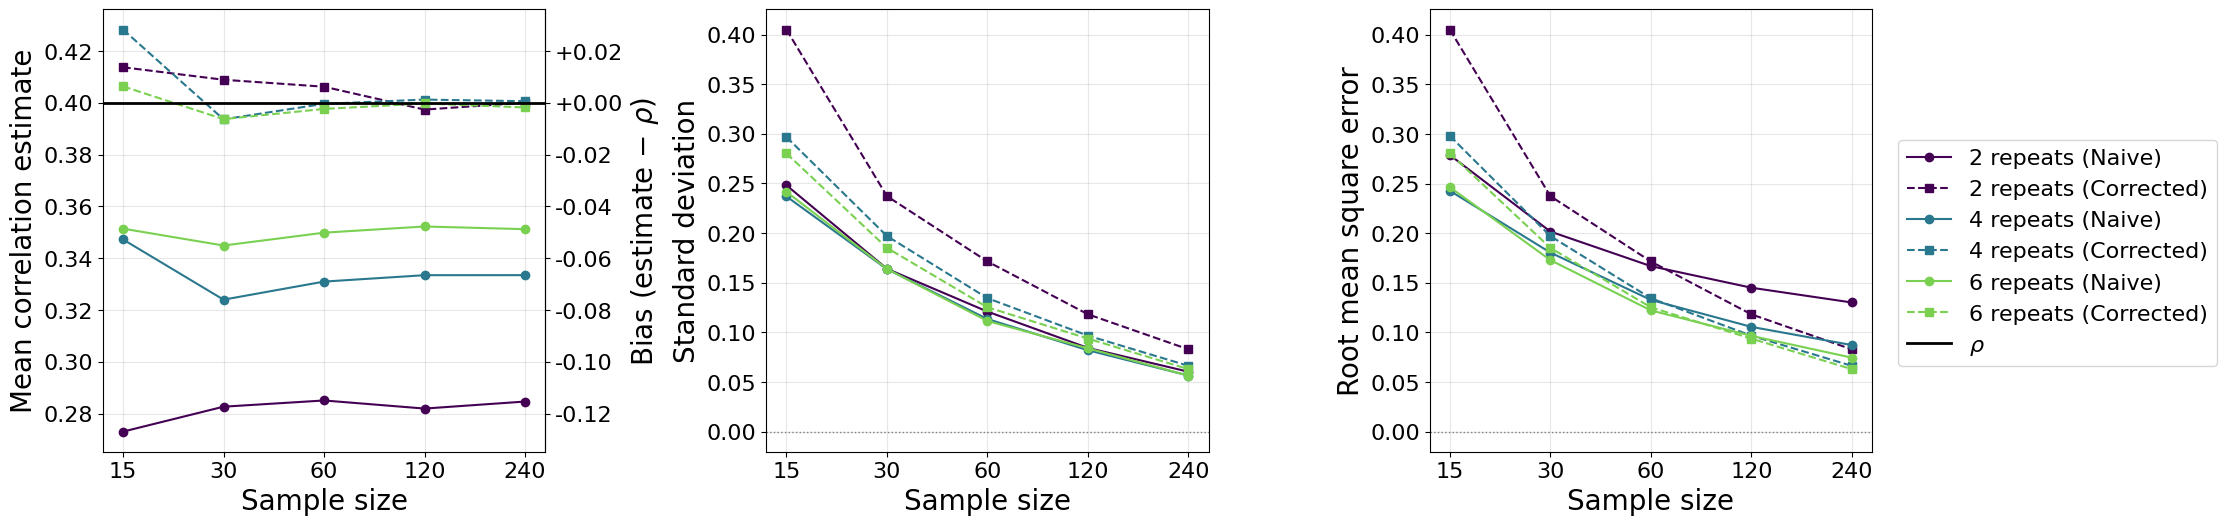

In [156]:
# --- Simulation ---
true_correlation = 0.4
task1_params = TaskParameters(between_var=0.5, within_var=0.4, name='task1')
task2_params = TaskParameters(between_var=0.5, within_var=0.4, name='task2')

grid_results = run_simulation_grid(
    task1_params, task2_params,
    sample_sizes=[15, 30, 60, 120, 240],
    n_repeats_list=[2, 4, 6],
    true_correlation=true_correlation,
    n_iterations=1000,
    random_state=None,
)
fig = plot_simulation_summary(grid_results)
plt.show()

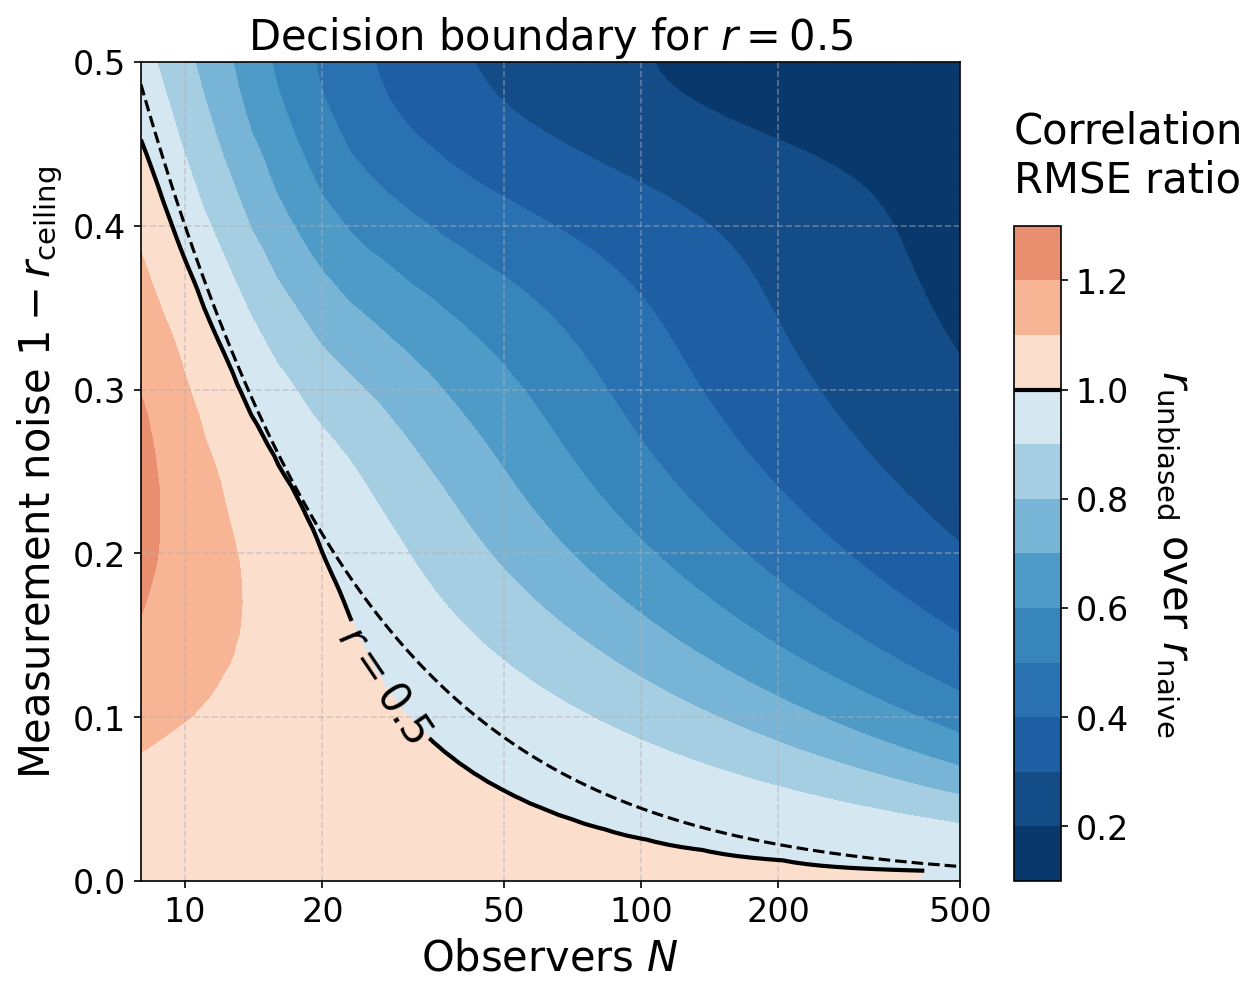

In [228]:
# --- Decision boundaries ---
# method='simulation' (default): exact Monte Carlo incl. reliability-estimation error, clipped to [-1, 1]
# method='known': original closed form (eqs. 4-6)
fig = plot_rmse_ratio_heatmap(r_value=0.5, k=2, method='simulation', show_known_boundary=True)
plt.show()

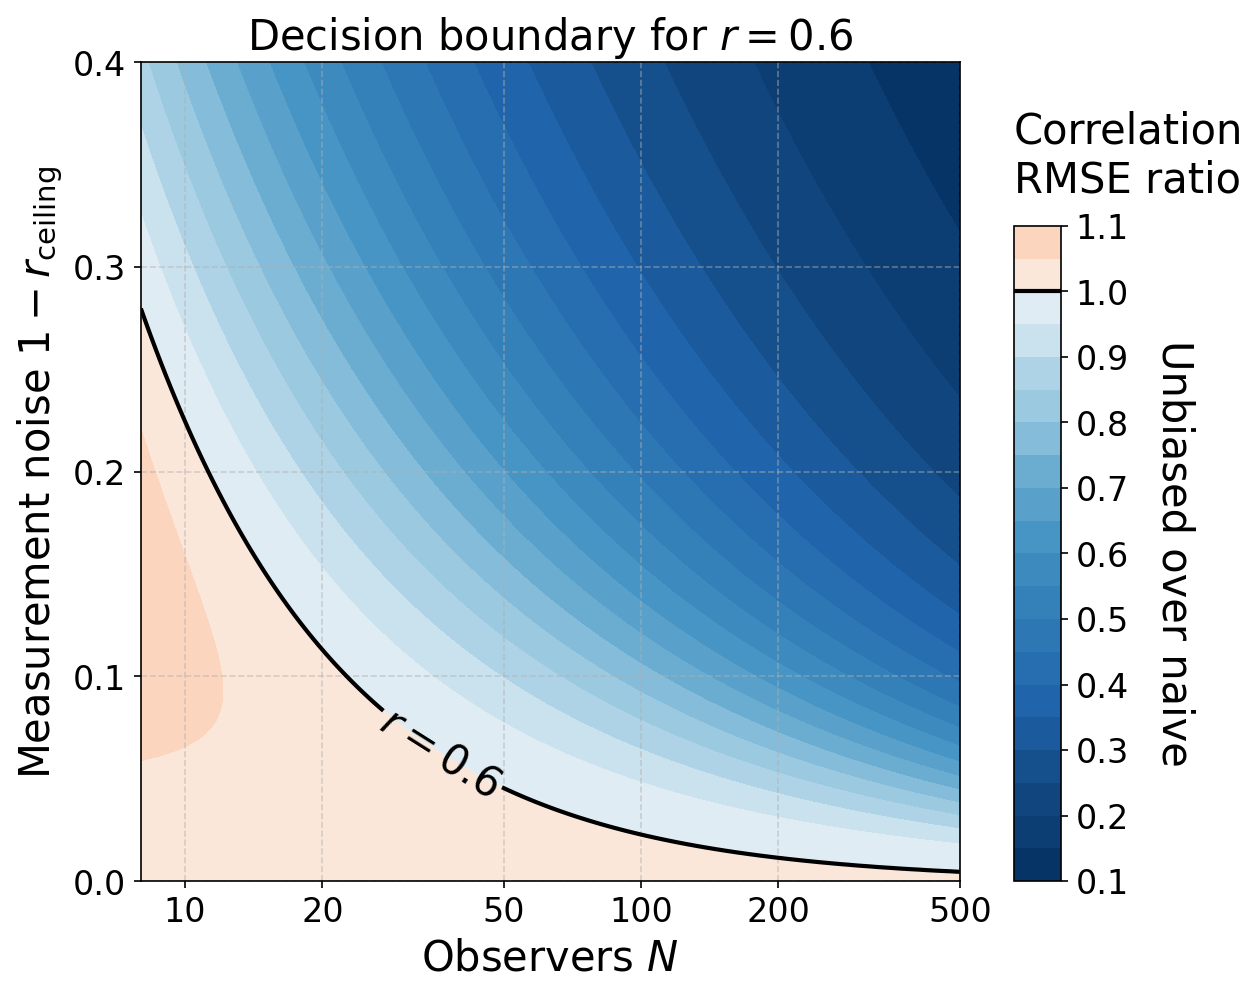

In [238]:
fig = plot_rmse_ratio_heatmap(r_value=0.6, k=2, method='known')
plt.show()

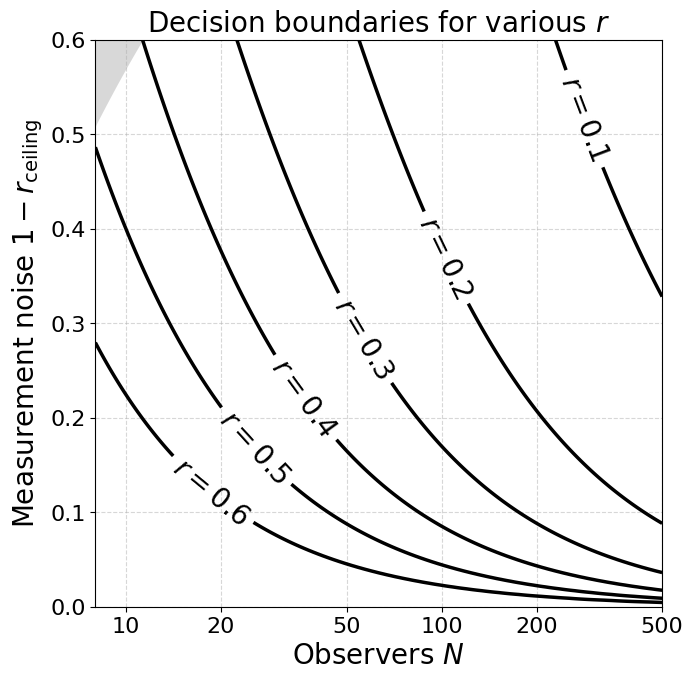

In [232]:
fig = plot_rmse_ratio_contours(r_values=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6), k=2, 
                               method='known', show_known_boundaries=False,
                               noise_max=0.6)
plt.show()

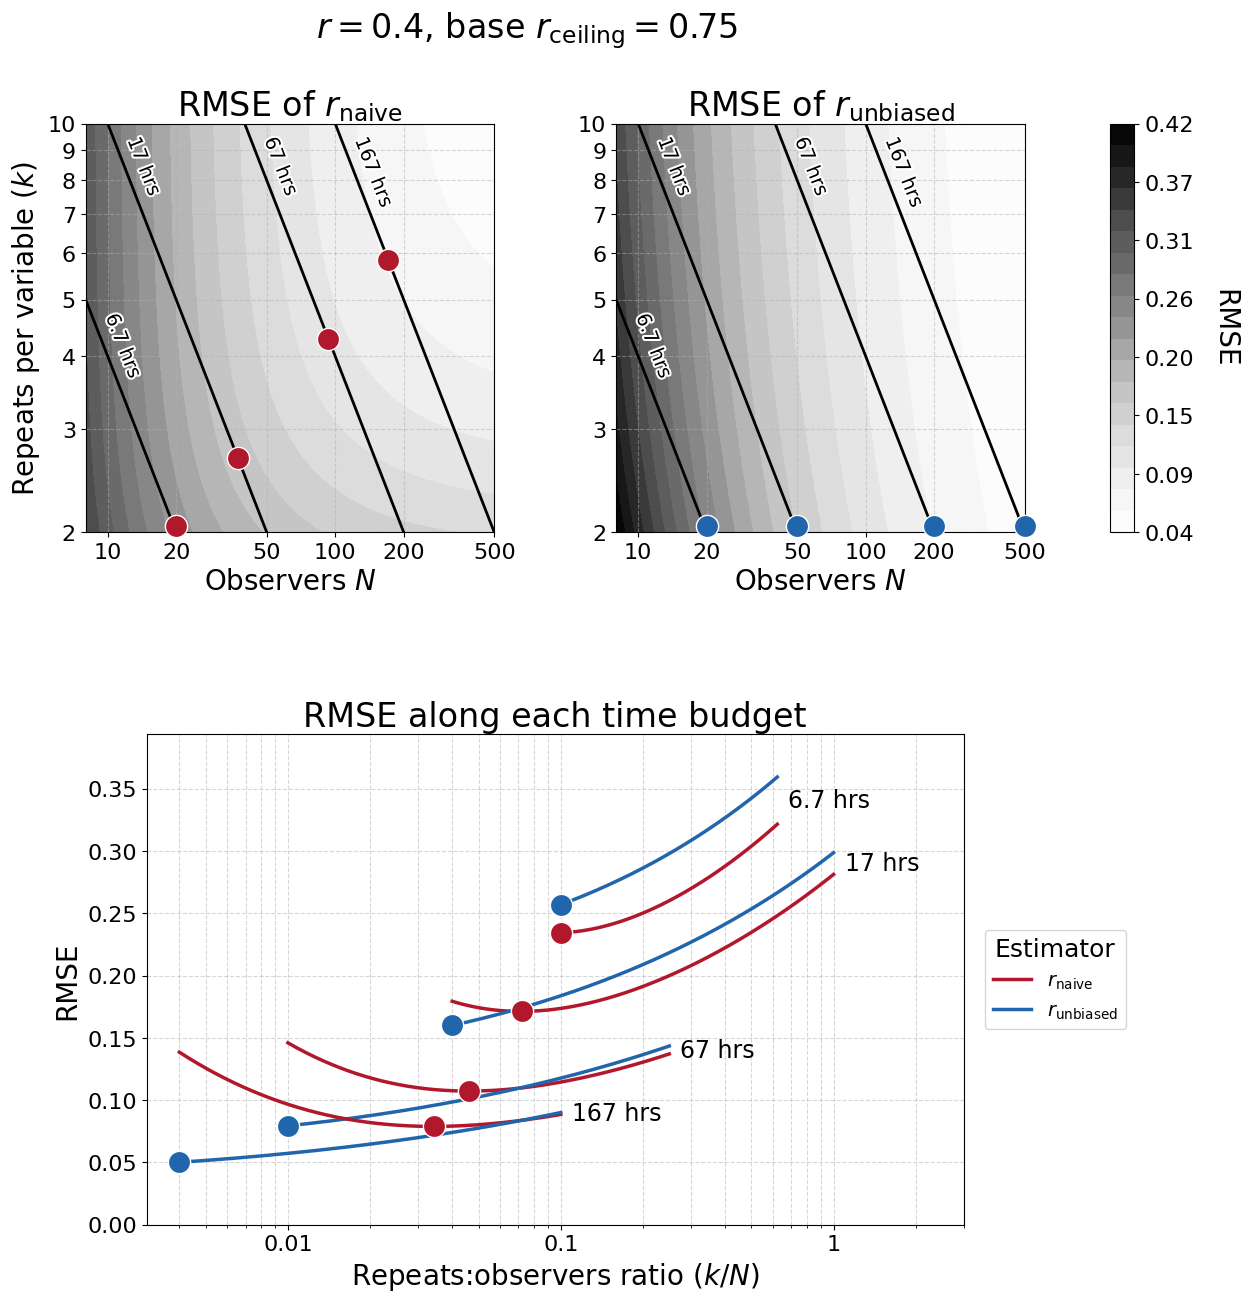

In [153]:
# --- Analytic RMSE over N and k with iso-time lines ---
# Iso-time budgets in minutes. 400 min = N = 20 at k = 2 (20 subjects × 20 min).
# Up to four budgets get distinct line styles.
fig = plot_rmse_heatmaps(r_values=[0.4], base_r_ceiling=0.75, base_k=2, iso_times=[400, 1000, 4000, 10000])
plt.show()

# fig = plot_rmse_heatmaps(r_values=[0.2, 0.3, 0.4, 0.5])   # multi-row version
# plt.show()

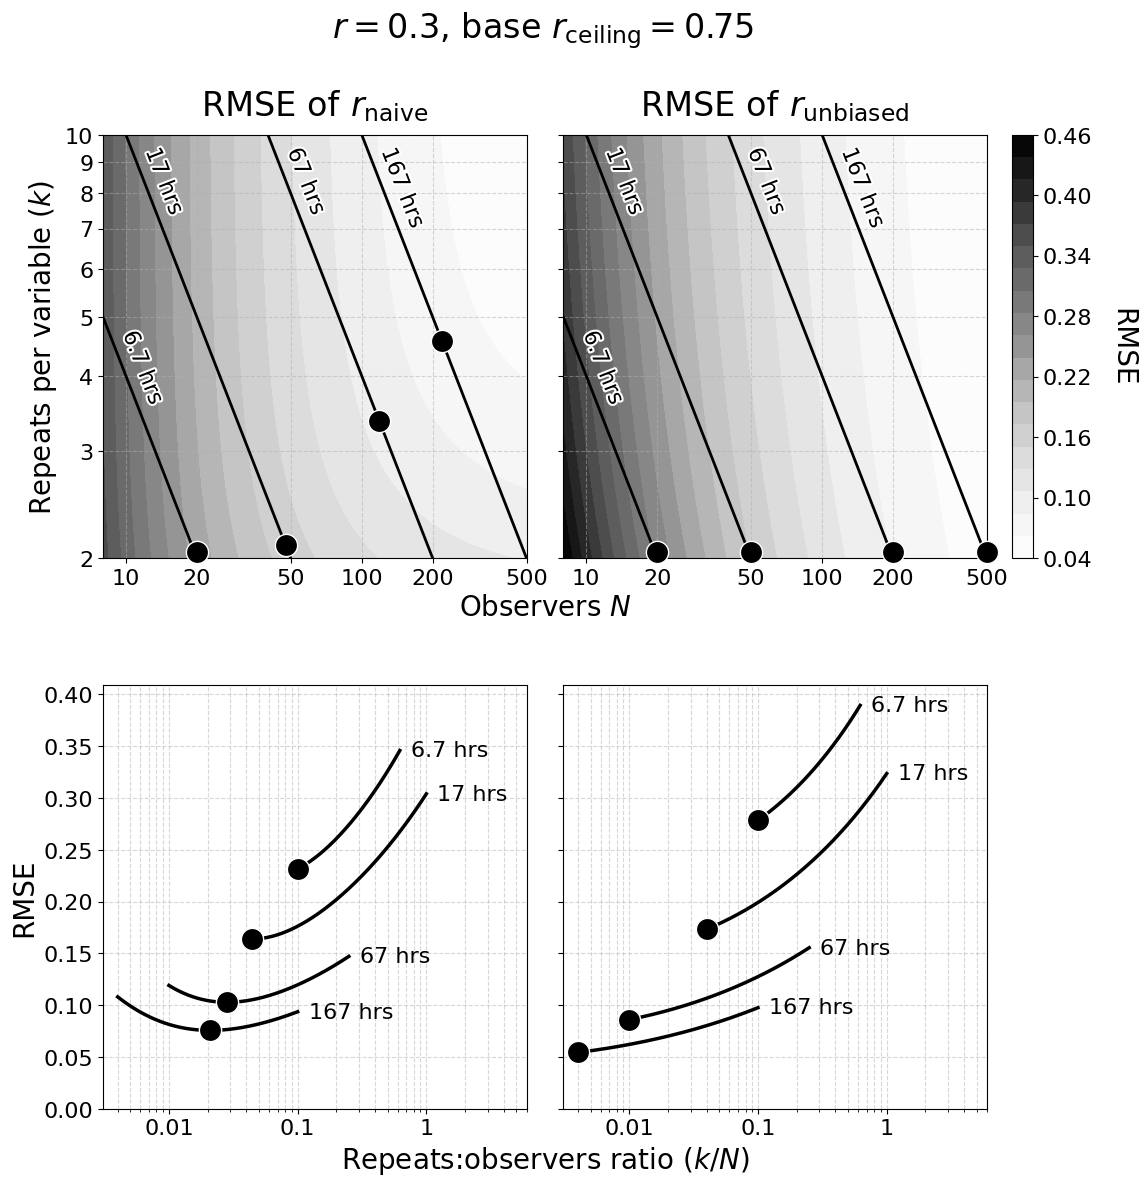

In [154]:
fig = plot_rmse_heatmaps_split(r_values=[0.3], base_r_ceiling=0.75, base_k=2,
                               iso_times=[400, 1000, 4000, 10000],
                               column_colors=('black', 'black'))
                               #column_colors=('#b2182b', '#2166ac'))
plt.show()

In [45]:
# --- Sanity check: Spearman-Brown scaling of r_ceiling with k ---
# (Jon's guess for k=4 from base 0.75 at k=2 was 1 - 0.25/1.7 = 0.853.)
pd.DataFrame({'k': [2, 4, 6, 8, 10],
              'r_ceiling': [calculate_r_ceiling_from_k(k, 0.75, 2) for k in [2, 4, 6, 8, 10]]})

,k,r_ceiling
0,2,0.750000
1,4,0.857143
2,6,0.900000
3,8,0.923077
4,10,0.937500
